# Módulo B — Series de tiempo: demanda diaria de órdenes

**Pregunta de negocio:** ¿cuántas órdenes recibirá Olist cada día durante las próximas 4 semanas?

**Estructura del notebook**

1. Configuración y funciones auxiliares
2. Construcción de la serie con SQL y período útil
3. Análisis de la serie (tendencia, estacionalidad, STL, ADF/KPSS, ACF/PACF)
4. Eventos atípicos y su tratamiento
5. Partición: prueba = últimas 8 semanas, validación *walk-forward*
6. Baselines (ingenuo e ingenuo estacional)
7. Modelo estadístico: SARIMA / SARIMAX
8. Modelo de ML: LightGBM con estrategia directa
9. Comparación en validación y selección
10. Evaluación final en prueba (una sola vez) y error por horizonte
11. Incertidumbre: intervalos paramétricos y conformales, cobertura empírica
12. Pronóstico operativo de las 4 semanas siguientes al cierre
13. Extensión opcional: serie de São Paulo
14. Conclusiones

Regla del taller: **toda la lectura de datos se hace con SQL** sobre `olist.duckdb` en modo solo lectura. Las consultas principales están en `sql/B_01_serie_diaria.sql`, `sql/B_02_calendario.sql` y `sql/B_03_features_ml.sql`; las fechas de corte se pasan como parámetros `?`.

## 1. Configuración

Todas las fechas de corte se declaran aquí una sola vez y se pasan como parámetros a las consultas. Si el Módulo 0 del grupo define otro período útil, basta con cambiar `FECHA_INICIO` / `FECHA_FIN`.

In [1]:
import warnings
from functools import partial
from pathlib import Path

import duckdb
import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")          # avisos de convergencia/índices de statsmodels
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# --- Rutas relativas (el notebook vive en notebooks/) ---
RAIZ = Path("..")
RUTA_DB = RAIZ / "data" / "olist.duckdb"
RUTA_SQL = RAIZ / "sql"
RUTA_FIG = RAIZ / "informe" / "figuras"
RUTA_RES = RAIZ / "resultados"
RUTA_FIG.mkdir(parents=True, exist_ok=True)
RUTA_RES.mkdir(parents=True, exist_ok=True)

SEMILLA = 42
np.random.seed(SEMILLA)

# --- Período útil y partición (ver justificación en la sección 2 y 5) ---
FECHA_INICIO = pd.Timestamp("2017-01-01")    # inicio del período útil (Módulo 0)
FECHA_FIN = pd.Timestamp("2018-08-19")       # último día completo antes del truncamiento
INICIO_AJUSTE = pd.Timestamp("2017-02-01")   # los modelos se ajustan desde aquí (enero = arranque)
H = 28                                        # horizonte: 4 semanas
UN_DIA = pd.Timedelta(days=1)

INICIO_TEST = FECHA_FIN - pd.Timedelta(days=8 * 7 - 1)            # últimas 8 semanas
ORIGENES_TEST = pd.date_range(INICIO_TEST - UN_DIA, FECHA_FIN - pd.Timedelta(days=H), freq="7D")
ORIGENES_VAL = pd.date_range("2018-01-07", INICIO_TEST - pd.Timedelta(days=H + 1), freq="7D")

print(f"Prueba: {INICIO_TEST.date()} a {FECHA_FIN.date()} ({(FECHA_FIN - INICIO_TEST).days + 1} días)")
print(f"Orígenes de validación: {len(ORIGENES_VAL)} ({ORIGENES_VAL[0].date()} ... {ORIGENES_VAL[-1].date()})")
print(f"Orígenes de prueba:     {len(ORIGENES_TEST)} ({ORIGENES_TEST[0].date()} ... {ORIGENES_TEST[-1].date()})")

Prueba: 2018-06-25 a 2018-08-19 (56 días)
Orígenes de validación: 21 (2018-01-07 ... 2018-05-27)
Orígenes de prueba:     5 (2018-06-24 ... 2018-07-22)


In [2]:
# --- Estilo de gráficos: líneas finas, grilla recesiva, colores fijos por modelo ---
COLOR_REAL = "#2b2b2b"
COLOR_TENUE = "#8a8984"
COLORES = {
    "SARIMAX": "#2a78d6",
    "LightGBM": "#eb6834",
    "SARIMA": "#1baf7a",
    "Ingenuo estacional": "#eda100",
    "Ingenuo": "#e87ba4",
}
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": COLOR_TENUE,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.6, "legend.frameon": False, "font.size": 10,
})


def formato_fechas(ax, semanas=1):
    """Marcas de eje cada `semanas` lunes, formato día-mes (evita etiquetas encimadas)."""
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=semanas))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))


def guardar(fig, nombre):
    """Guarda la figura para el informe."""
    fig.savefig(RUTA_FIG / f"{nombre}.png")


# --- Acceso a datos: siempre SQL desde archivos .sql ---
def leer_sql(nombre):
    return (RUTA_SQL / nombre).read_text(encoding="utf-8")


def consultar(con, nombre, params=None):
    """Ejecuta un archivo .sql con parámetros posicionales (?) y devuelve un DataFrame."""
    return con.execute(leer_sql(nombre), params or []).df()


def crear_tabla_temporal(con, tabla, nombre, params=None):
    """Materializa una consulta como tabla TEMPORAL en memoria (no toca olist.duckdb)."""
    sql = leer_sql(nombre).strip().rstrip(";")
    con.execute(f"CREATE OR REPLACE TEMP TABLE {tabla} AS {sql}", params or [])


con = duckdb.connect(str(RUTA_DB), read_only=True)
print(con.sql("SHOW TABLES"))

┌──────────────────────┐
│         name         │
│       varchar        │
├──────────────────────┤
│ category_translation │
│ customers            │
│ geolocation          │
│ order_items          │
│ order_payments       │
│ order_reviews        │
│ orders               │
│ products             │
│ sellers              │
└──────────────────────┘



## 2. Construcción de la serie y período útil

`B_01_serie_diaria.sql` arma una **grilla de días** con `generate_series` y la une con `LEFT JOIN` a los conteos por día de `order_purchase_timestamp`; así los días sin órdenes quedan con 0 en lugar de desaparecer (lo que rompería los rezagos y la estacionalidad semanal).

Decisión: se cuentan **todas** las órdenes, sin filtrar `order_status`. La pregunta es de planeación de demanda: una orden cancelada o no disponible también consumió capacidad de atención y es demanda recibida. Las canceladas + no disponibles son ~1.2 % del total, así que la decisión no cambia la forma de la serie.

Primero se mira la serie **completa** del dataset para justificar el recorte.

Compras entre 2016-09-04 y 2018-10-17


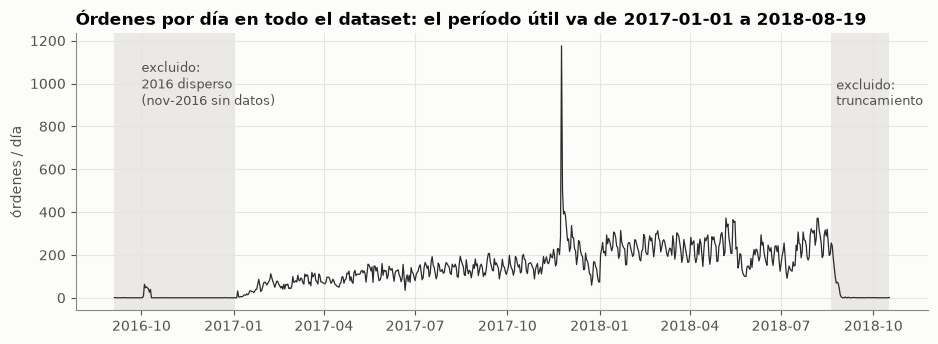

Días con órdenes 0 entre 2016-09 y 2016-12: 104 de 119


fecha,2018-08-13,2018-08-14,2018-08-15,2018-08-16,2018-08-17,2018-08-18,2018-08-19,2018-08-20,2018-08-21,2018-08-22,2018-08-23,2018-08-24,2018-08-25,2018-08-26,2018-08-27,2018-08-28,2018-08-29,2018-08-30,2018-08-31,2018-09-01,2018-09-02,2018-09-03,2018-09-04,2018-09-05
n_ordenes,292,316,288,320,257,198,204,256,243,187,144,99,69,73,67,44,14,4,1,0,0,4,0,0


In [3]:
# Rango total de compras en la base (para no escribir fechas a mano)
minimo, maximo = con.execute("""
    SELECT CAST(MIN(order_purchase_timestamp) AS DATE),
           CAST(MAX(order_purchase_timestamp) AS DATE)
    FROM orders
""").fetchone()
print("Compras entre", minimo, "y", maximo)

serie_cruda = consultar(con, "B_01_serie_diaria.sql", [minimo, maximo, None])
serie_cruda["fecha"] = pd.to_datetime(serie_cruda["fecha"])
y_cruda = serie_cruda.set_index("fecha")["n_ordenes"]

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(y_cruda.index, y_cruda.values, color=COLOR_REAL, lw=0.9)
ax.axvspan(y_cruda.index[0], FECHA_INICIO, color="#e6e5e0", alpha=0.8, lw=0)
ax.axvspan(FECHA_FIN + UN_DIA, y_cruda.index[-1], color="#e6e5e0", alpha=0.8, lw=0)
ax.text(pd.Timestamp("2016-10-01"), 900, "excluido:\n2016 disperso\n(nov-2016 sin datos)", color="#52514e", fontsize=9)
ax.text(pd.Timestamp("2018-08-25"), 900, "excluido:\ntruncamiento", color="#52514e", fontsize=9)
ax.set_title("Órdenes por día en todo el dataset: el período útil va de 2017-01-01 a 2018-08-19")
ax.set_ylabel("órdenes / día")
guardar(fig, "B_00_serie_cruda")
plt.show()

print("Días con órdenes 0 entre 2016-09 y 2016-12:", int((y_cruda[:"2016-12-31"] == 0).sum()), "de", len(y_cruda[:"2016-12-31"]))
y_cruda["2018-08-13":"2018-09-05"].to_frame().T

**Decisión — período útil 2017-01-01 a 2018-08-19.**

* **Inicio:** 2016 tiene solo ~330 órdenes repartidas en septiembre, octubre y un día de diciembre, con todo noviembre en cero: es un piloto, no la operación. Empezar en 2017-01-01 además coincide con el inicio del entrenamiento del Módulo A.
* **Fin:** a partir del 22-ago-2018 los conteos caen de ~290 a menos de 20 diarios en una semana. No es demanda real sino el **corte del extracto** (las órdenes de esos días aún no estaban todas registradas). Se toma como último día el **domingo 19-ago-2018**, la última semana completa antes de la caída, para que las 8 semanas de prueba sean semanas lunes–domingo completas.
* **Ajuste desde 2017-02-01:** enero de 2017 es el arranque de la plataforma (4 días en cero, luego 5–35 órdenes/día). En escala logarítmica esos valores generan saltos enormes que inflarían la varianza estimada del SARIMAX y sus intervalos. Enero se conserva en la serie (sirve como historia para las ventanas de 91 días del modelo de ML) pero ningún modelo lo usa como objetivo.

In [4]:
serie = consultar(con, "B_01_serie_diaria.sql", [FECHA_INICIO.date(), FECHA_FIN.date(), None])
serie["fecha"] = pd.to_datetime(serie["fecha"])
y = serie.set_index("fecha")["n_ordenes"].asfreq("D")

# Calendario: se extiende H días más allá del cierre para el pronóstico operativo
cal = consultar(con, "B_02_calendario.sql", [FECHA_INICIO.date(), (FECHA_FIN + pd.Timedelta(days=H)).date()])
cal["fecha"] = pd.to_datetime(cal["fecha"])
cal = cal.set_index("fecha").asfreq("D")

# Validaciones de la serie
total_sql = con.execute(
    "SELECT COUNT(*) FROM orders WHERE order_purchase_timestamp >= ? AND order_purchase_timestamp < ?",
    [FECHA_INICIO.date(), (FECHA_FIN + UN_DIA).date()],
).fetchone()[0]
assert len(y) == (FECHA_FIN - FECHA_INICIO).days + 1, "faltan días en la grilla"
assert y.isna().sum() == 0
assert y.sum() == total_sql, "el JOIN con customers duplicó o perdió órdenes"

print(f"Días: {len(y)} | órdenes: {y.sum():,} (cuadra con orders: {total_sql:,})")
print("Días con 0 órdenes:", list(y[y == 0].index.date))
y.describe().round(1).to_frame().T

Días: 596 | órdenes: 97,891 (cuadra con orders: 97,891)
Días con 0 órdenes: [datetime.date(2017, 1, 1), datetime.date(2017, 1, 2), datetime.date(2017, 1, 3), datetime.date(2017, 1, 4)]


,count,mean,std,min,25%,50%,75%,max
n_ordenes,596.0,164.2,90.9,0.0,104.8,152.5,218.2,1176.0


## 3. Análisis de la serie

### 3.1 Tendencia y estacionalidad semanal

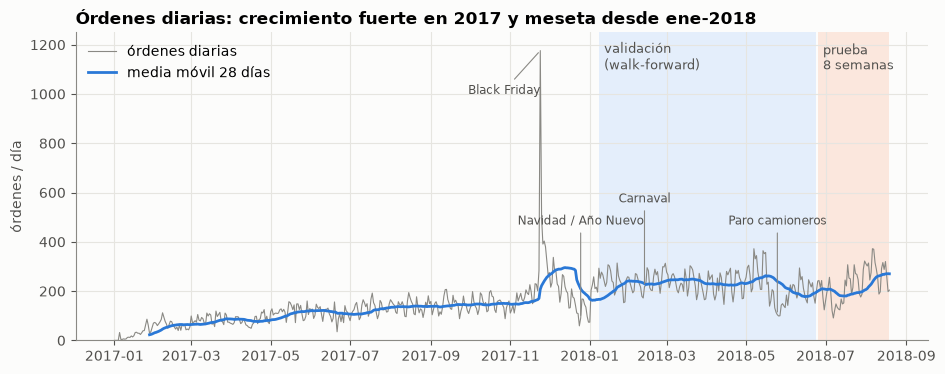

Promedio diario por mes:
 fecha
2017-02-01     63.6
2017-03-01     86.5
2017-04-01     80.1
2017-05-01    119.4
2017-06-01    108.2
2017-07-01    129.9
2017-08-01    139.7
2017-09-01    142.8
2017-10-01    149.4
2017-11-01    251.5
2017-12-01    183.0
2018-01-01    234.5
2018-02-01    240.3
2018-03-01    232.6
2018-04-01    231.3
2018-05-01    221.7
2018-06-01    205.6
2018-07-01    203.0
2018-08-01    279.5
Freq: MS


In [5]:
# (etiqueta, fecha, altura del texto)
EVENTOS_PLOT = [("Black Friday", "2017-11-24", 1000), ("Navidad / Año Nuevo", "2017-12-25", 470),
                ("Carnaval", "2018-02-12", 560), ("Paro camioneros", "2018-05-25", 470)]
media_28 = y.rolling(28).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index, y.values, color=COLOR_TENUE, lw=0.8, label="órdenes diarias")
ax.plot(media_28.index, media_28.values, color=COLORES["SARIMAX"], lw=2, label="media móvil 28 días")
ax.axvspan(ORIGENES_VAL[0] + UN_DIA, INICIO_TEST - UN_DIA, color="#cde2fb", alpha=0.5, lw=0)
ax.axvspan(INICIO_TEST, FECHA_FIN, color="#fbd9c9", alpha=0.6, lw=0)
ax.text(ORIGENES_VAL[0] + pd.Timedelta(days=5), 1100, "validación\n(walk-forward)", fontsize=9, color="#52514e")
ax.text(INICIO_TEST + pd.Timedelta(days=4), 1100, "prueba\n8 semanas", fontsize=9, color="#52514e")
for nombre, fecha, altura in EVENTOS_PLOT:
    f = pd.Timestamp(fecha)
    ax.annotate(nombre, (f, y[f]), xytext=(f, altura), ha="right" if nombre == "Black Friday" else "center",
                fontsize=8.5, color="#52514e", arrowprops=dict(arrowstyle="-", color=COLOR_TENUE, lw=0.8))
ax.set_ylim(0, 1250)
ax.set_title("Órdenes diarias: crecimiento fuerte en 2017 y meseta desde ene-2018")
ax.set_ylabel("órdenes / día")
ax.legend(loc="upper left")
guardar(fig, "B_01_serie")
plt.show()

mensual = y[INICIO_AJUSTE:].resample("MS").mean().round(1)
print("Promedio diario por mes:\n", mensual.to_string())

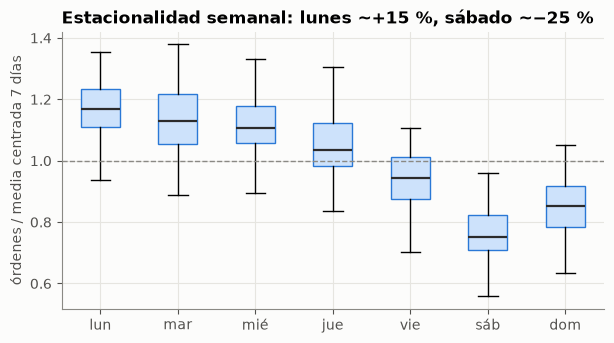

,lun,mar,mié,jue,vie,sáb,dom
mean,1.168,1.130,1.102,1.050,0.949,0.766,0.856
std,0.133,0.132,0.159,0.113,0.104,0.092,0.098


In [6]:
# Perfil semanal: razón de cada día contra la media centrada de 7 días (excluye días atípicos)
atipico = cal.loc[y.index, ["black_friday", "post_black_friday", "fiestas_fin_anio", "paro_camioneros", "es_feriado"]].sum(axis=1) > 0
razon = (y / y.rolling(7, center=True).mean())[INICIO_AJUSTE:]
razon = razon[~atipico[INICIO_AJUSTE:]].dropna()
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
perfil = razon.groupby(razon.index.dayofweek).agg(["mean", "std"]).round(3)
perfil.index = DIAS

fig, ax = plt.subplots(figsize=(7, 3.6))
datos = [razon[razon.index.dayofweek == d].values for d in range(7)]
bp = ax.boxplot(datos, tick_labels=DIAS, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color=COLOR_REAL, lw=1.6))
for caja in bp["boxes"]:
    caja.set(facecolor="#cde2fb", edgecolor=COLORES["SARIMAX"], lw=1)
ax.axhline(1, color=COLOR_TENUE, lw=1, ls="--")
ax.set_title("Estacionalidad semanal: lunes ~+15 %, sábado ~−25 %")
ax.set_ylabel("órdenes / media centrada 7 días")
guardar(fig, "B_02_perfil_semanal")
plt.show()
perfil.T

### 3.2 Descomposición STL

Se descompone `log(1 + y)` con STL (periodo 7, versión robusta). Se usa el **logaritmo** porque la amplitud semanal crece con el nivel (la serie triplicó su volumen en 2017): en log la estacionalidad pasa de multiplicativa a aditiva. La versión robusta evita que Black Friday deforme la tendencia.

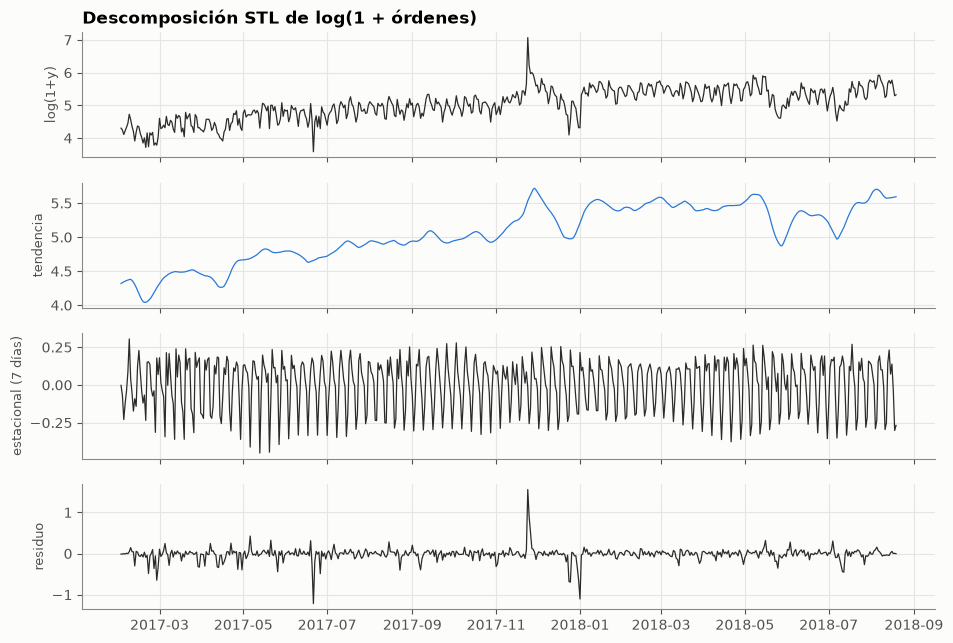

Fuerza de la tendencia: 0.88 | fuerza de la estacionalidad semanal: 0.46


In [7]:
ylog = np.log1p(y[INICIO_AJUSTE:])
stl = STL(ylog, period=7, robust=True).fit()

fig, ejes = plt.subplots(4, 1, figsize=(11, 7.5), sharex=True)
for ax, (nombre, comp) in zip(ejes, [("log(1+y)", ylog), ("tendencia", stl.trend),
                                     ("estacional (7 días)", stl.seasonal), ("residuo", stl.resid)]):
    ax.plot(comp.index, comp.values, color=COLOR_REAL if nombre != "tendencia" else COLORES["SARIMAX"], lw=0.9)
    ax.set_ylabel(nombre, fontsize=9)
ejes[0].set_title("Descomposición STL de log(1 + órdenes)")
guardar(fig, "B_03_stl")
plt.show()

# Fuerza de tendencia y estacionalidad (Hyndman & Athanasopoulos, FPP3 §4.3)
var_r = np.var(stl.resid)
fuerza_t = max(0, 1 - var_r / np.var(stl.trend + stl.resid))
fuerza_s = max(0, 1 - var_r / np.var(stl.seasonal + stl.resid))
print(f"Fuerza de la tendencia: {fuerza_t:.2f} | fuerza de la estacionalidad semanal: {fuerza_s:.2f}")

### 3.3 Estacionariedad: ADF y KPSS

Las dos pruebas tienen hipótesis nulas opuestas, por eso se usan juntas:

* **ADF** — H0: hay raíz unitaria (no estacionaria). Rechazar (p < 0.05) apoya estacionariedad.
* **KPSS** — H0: la serie es estacionaria. Rechazar (p < 0.05) indica no estacionariedad.

(KPSS reporta p truncado al rango [0.01, 0.10].)

In [8]:
def pruebas_estacionariedad(serie, nombre):
    adf_est, adf_p, *_ = adfuller(serie.dropna(), autolag="AIC")
    kpss_est, kpss_p, *_ = kpss(serie.dropna(), regression="c", nlags="auto")
    if adf_p < 0.05 and kpss_p > 0.05:
        concl = "estacionaria"
    elif adf_p >= 0.05 and kpss_p <= 0.05:
        concl = "NO estacionaria"
    else:
        concl = "ambigua"
    return {"serie": nombre, "ADF": round(adf_est, 2), "p ADF": round(adf_p, 4),
            "KPSS": round(kpss_est, 2), "p KPSS": round(kpss_p, 3), "conclusión": concl}


d1 = ylog.diff()
d1_d7 = ylog.diff().diff(7)
tabla_est = pd.DataFrame([
    pruebas_estacionariedad(ylog, "log(1+y)"),
    pruebas_estacionariedad(d1, "Δ log(1+y)"),
    pruebas_estacionariedad(d1_d7, "Δ Δ7 log(1+y)"),
])
tabla_est

,serie,ADF,p ADF,KPSS,p KPSS,conclusión
0,log(1+y),-2.40,0.1404,2.78,0.01,NO estacionaria
1,Δ log(1+y),-7.64,0.0000,0.13,0.10,estacionaria
2,Δ Δ7 log(1+y),-9.78,0.0000,0.02,0.10,estacionaria


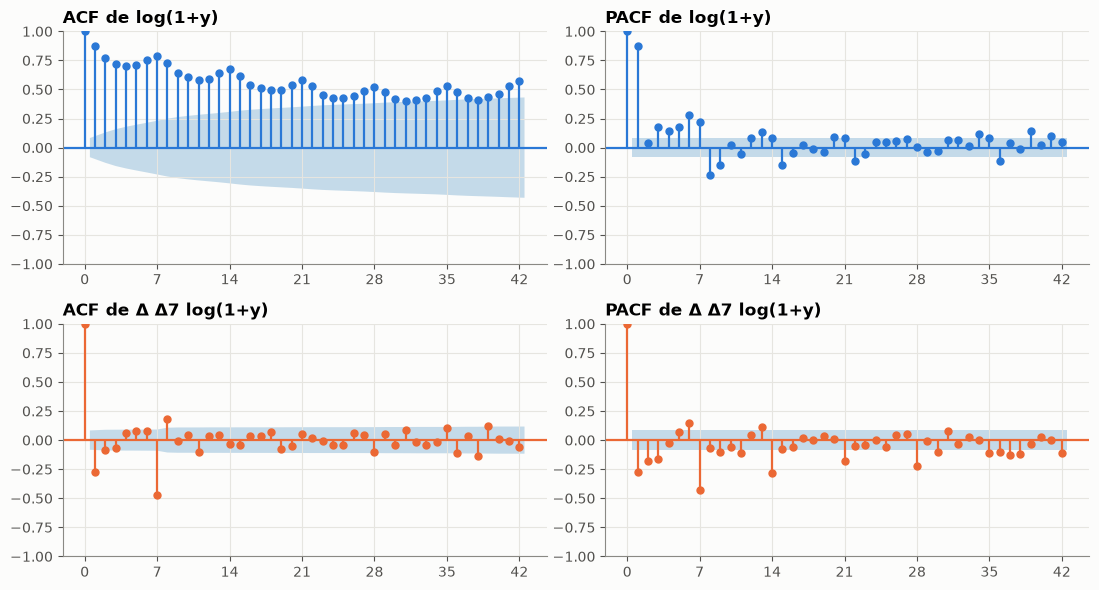

In [9]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 6))
plot_acf(ylog, lags=42, ax=ejes[0, 0], color=COLORES["SARIMAX"], vlines_kwargs={"colors": COLORES["SARIMAX"]})
plot_pacf(ylog, lags=42, ax=ejes[0, 1], method="ywm", color=COLORES["SARIMAX"], vlines_kwargs={"colors": COLORES["SARIMAX"]})
plot_acf(d1_d7.dropna(), lags=42, ax=ejes[1, 0], color=COLORES["LightGBM"], vlines_kwargs={"colors": COLORES["LightGBM"]})
plot_pacf(d1_d7.dropna(), lags=42, ax=ejes[1, 1], method="ywm", color=COLORES["LightGBM"], vlines_kwargs={"colors": COLORES["LightGBM"]})
ejes[0, 0].set_title("ACF de log(1+y)")
ejes[0, 1].set_title("PACF de log(1+y)")
ejes[1, 0].set_title("ACF de Δ Δ7 log(1+y)")
ejes[1, 1].set_title("PACF de Δ Δ7 log(1+y)")
for ax in ejes.flat:
    ax.set_xticks(range(0, 43, 7))
fig.tight_layout()
guardar(fig, "B_04_acf_pacf")
plt.show()

**Lectura.** La ACF del nivel decae muy lento (persistencia/tendencia) con picos en los múltiplos de 7; tras una diferencia regular y una estacional (Δ Δ7) la ACF queda con un pico negativo en el rezago 1 y en el 7 y la PACF decae en los múltiplos de 7: es la firma clásica de un componente **MA(1) regular y MA(1) estacional**, el modelo "aerolínea" SARIMA(0,1,1)(0,1,1)₇. Este patrón orienta la grilla de órdenes del SARIMAX (sección 7), que se elige por AIC.

## 4. Eventos atípicos

Para cada evento se compara lo observado contra lo **esperado**, definido como la mediana del mismo día de la semana en las 4 semanas previas.

In [10]:
def esperado_mismo_dia(serie, fecha, semanas=4):
    previos = [fecha - pd.Timedelta(days=7 * k) for k in range(1, semanas + 1)]
    return serie.reindex(previos).median()


BANDERAS = ["es_feriado", "black_friday", "post_black_friday", "fiestas_fin_anio", "paro_camioneros", "partido_brasil"]
filas = []
for bandera in BANDERAS:
    dias = cal.index[(cal[bandera] == 1) & (cal.index >= INICIO_AJUSTE) & (cal.index <= FECHA_FIN)]
    obs = y.reindex(dias)
    esp = pd.Series([esperado_mismo_dia(y, d) for d in dias], index=dias)
    filas.append({"evento": bandera, "días": len(dias), "observado": int(obs.sum()),
                  "esperado": int(esp.sum()), "razón obs/esp": round(obs.sum() / esp.sum(), 2),
                  "razón mín": round((obs / esp).min(), 2), "razón máx": round((obs / esp).max(), 2)})
tabla_eventos = pd.DataFrame(filas).set_index("evento")
tabla_eventos

,días,observado,esperado,razón obs/esp,razón mín,razón máx
evento,,,,,,
es_feriado,18,2313,3110,0.74,0.30,1.47
black_friday,1,1176,154,7.64,7.64,7.64
post_black_friday,4,1673,656,2.55,2.03,3.84
fiestas_fin_anio,9,1010,1996,0.51,0.28,0.68
paro_camioneros,11,1519,2997,0.51,0.41,0.66
partido_brasil,5,862,1009,0.85,0.66,0.97


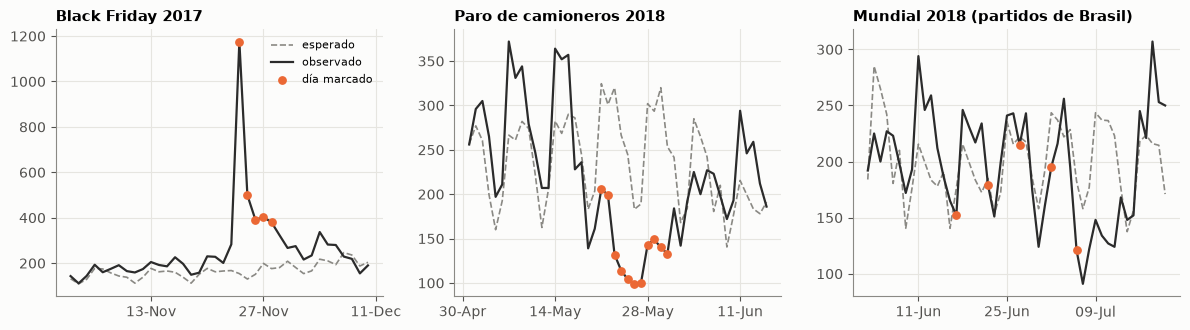

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=False)
ventanas = [("Black Friday 2017", "2017-11-03", "2017-12-10", ["black_friday", "post_black_friday"]),
            ("Paro de camioneros 2018", "2018-05-01", "2018-06-15", ["paro_camioneros"]),
            ("Mundial 2018 (partidos de Brasil)", "2018-06-03", "2018-07-20", ["partido_brasil"])]
for ax, (titulo, ini, fin, bands) in zip(ejes, ventanas):
    tramo = y[ini:fin]
    esp = pd.Series([esperado_mismo_dia(y, d) for d in tramo.index], index=tramo.index)
    ax.plot(tramo.index, esp.values, color=COLOR_TENUE, lw=1.2, ls="--", label="esperado")
    ax.plot(tramo.index, tramo.values, color=COLOR_REAL, lw=1.6, label="observado")
    marcados = tramo.index[cal.loc[tramo.index, bands].sum(axis=1) > 0]
    ax.scatter(marcados, tramo[marcados], color=COLORES["LightGBM"], s=28, zorder=3, label="día marcado")
    ax.set_title(titulo, fontsize=10.5)
    formato_fechas(ax, semanas=2)
ejes[0].legend(fontsize=8)
fig.tight_layout()
guardar(fig, "B_05_eventos")
plt.show()

**Decisión por evento** (modelar / marcar / excluir):

| Evento | Efecto observado | Tratamiento | Justificación |
|---|---|---|---|
| Black Friday (24-nov-2017) | ~4–5× lo esperado | **Modelar** (dummy `black_friday`) | Recurrente y con fecha conocida: el plan de capacidad de nov-2018 debe anticiparlo. Excluirlo subestimaría el pico siguiente. |
| Días posteriores a BF (25 a 28-nov) | +60 % a +90 % | **Modelar** (dummy `post_black_friday`) | Efecto de arrastre y Cyber Monday, también recurrente. |
| Feriados nacionales | caídas de 20–50 % | **Modelar** (dummy `es_feriado`) | Fechas conocidas con anticipación; se repiten cada año. |
| Navidad / fin de año (24-dic a 1-ene) | caída de ~40 % | **Modelar** (dummy `fiestas_fin_anio`) | Recurrente; distinto de un feriado de un solo día. |
| Paro de camioneros (21 a 31-may-2018) | caída de ~45 % | **Marcar** (dummy en el ajuste, se fija en 0 al pronosticar y se excluye de las métricas de validación) | No es recurrente ni previsible. La dummy evita que distorsione los parámetros; no penalizamos a los modelos por no prever algo imposible de prever. |
| Partidos de Brasil en el Mundial 2018 | −5 % a −30 % | **Solo diagnóstico** | Solo 2 partidos antes de la prueba (insuficiente para estimar un efecto) y las fechas de eliminatorias no se conocen al pronosticar. Se analiza su impacto en el error de prueba (sección 10). |
| Arranque ene-2017 y truncamiento ago-2018 | artefactos de los datos | **Excluir** | No representan demanda (sección 2). |

Las banderas viven en `sql/B_02_calendario.sql`, así que el mismo tratamiento se aplica al SARIMAX (variables exógenas) y al modelo de ML (variables de la fecha objetivo).

## 5. Partición y esquema *walk-forward*

* **Prueba:** últimas 8 semanas del período útil, **25-jun-2018 a 19-ago-2018**. Se evalúa con 5 orígenes semanales (cada domingo), cada uno pronosticando los 28 días siguientes sin salirse de la prueba. Así cada horizonte h = 1…28 tiene 5 pronósticos independientes en la prueba y se puede ver cómo crece el error con h. En cada origen el modelo se reajusta con los datos reales observados hasta ese domingo (es lo que pasaría en producción).
* **Validación:** *walk-forward* con origen móvil semanal sobre los datos anteriores a la prueba: 21 orígenes (domingos del 7-ene al 27-may-2018), horizonte 28 días, ventana de ajuste **expansiva** desde 2017-02-01. El último origen pronostica hasta el 24-jun, el día anterior a la prueba: la prueba nunca se toca para seleccionar.
* **Por qué orígenes desde enero 2018:** así cada modelo ya vio un Black Friday y una temporada de fin de año en su ventana de ajuste, y la validación cubre ~5 meses de condiciones distintas (Carnaval, Semana Santa, paro).
* **Por qué domingo:** el plan operativo se haría cada domingo para las 4 semanas siguientes (lunes a domingo).

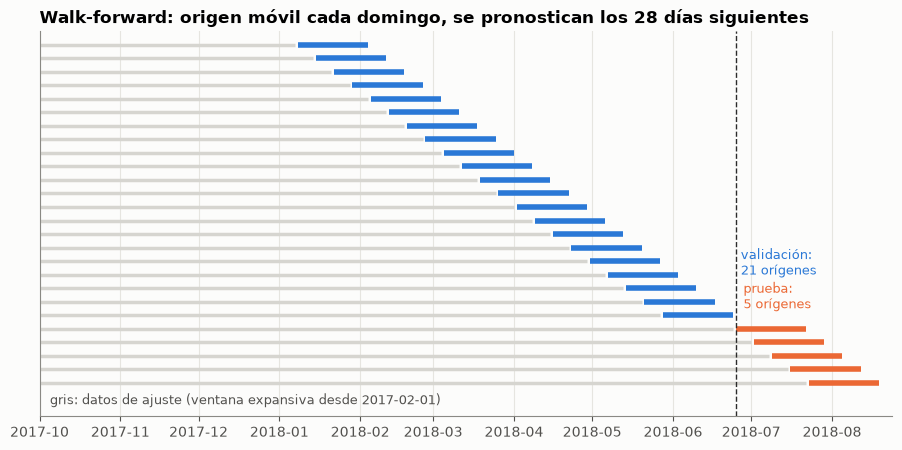

In [12]:
def walk_forward(serie, nombre, funcion, origenes, horizonte=H):
    """Aplica `funcion(origen, fechas)` en cada origen y junta los pronósticos con el valor real."""
    salida = []
    for o in origenes:
        fechas = pd.date_range(o + UN_DIA, periods=horizonte, freq="D")
        pred = funcion(o, fechas).reset_index(drop=True)
        pred["modelo"] = nombre
        pred["origen"] = o
        pred["fecha"] = fechas
        pred["horizonte"] = np.arange(1, horizonte + 1)
        pred["y"] = serie.reindex(fechas).values
        salida.append(pred)
    return pd.concat(salida, ignore_index=True)


def metricas(df, por=("modelo",)):
    """MAE, RMSE, MAPE y sMAPE agregados por las columnas indicadas."""
    e = df["y"] - df["yhat"]
    d = df.assign(ae=e.abs(), se=e ** 2, ape=100 * e.abs() / df["y"],
                  sape=200 * e.abs() / (df["y"].abs() + df["yhat"].abs()))
    r = d.groupby(list(por)).agg(MAE=("ae", "mean"), RMSE=("se", "mean"),
                                 MAPE=("ape", "mean"), sMAPE=("sape", "mean"), n=("ae", "size"))
    r["RMSE"] = np.sqrt(r["RMSE"])
    return r.round(2)


def semana_horizonte(df):
    return df.assign(semana_h="sem " + ((df["horizonte"] - 1) // 7 + 1).astype(str))


def sin_paro(df):
    """Quita los días objetivo del paro de camioneros (evento imprevisible)."""
    return df[cal.loc[df["fecha"], "paro_camioneros"].values == 0]


fig, ax = plt.subplots(figsize=(11, 5))
origenes = list(ORIGENES_VAL) + list(ORIGENES_TEST)
for i, o in enumerate(origenes):
    fila = len(origenes) - i
    color = COLORES["SARIMAX"] if o in ORIGENES_VAL else COLORES["LightGBM"]
    ax.plot([INICIO_AJUSTE, o], [fila, fila], color="#d6d5d0", lw=2.5, solid_capstyle="butt")
    ax.plot([o + UN_DIA, o + pd.Timedelta(days=H)], [fila, fila], color=color, lw=4, solid_capstyle="butt")
ax.axvline(INICIO_TEST, color=COLOR_REAL, lw=1, ls="--")
ax.text(pd.Timestamp("2017-10-05"), -0.6, "gris: datos de ajuste (ventana expansiva desde 2017-02-01)", color="#52514e", fontsize=9)
ax.set_ylim(-1.5, len(origenes) + 1)
ax.text(ORIGENES_VAL[-1] + pd.Timedelta(days=H + 3), 9, "validación:\n21 orígenes", color=COLORES["SARIMAX"], fontsize=9)
ax.text(INICIO_TEST + pd.Timedelta(days=3), 6.5, "prueba:\n5 orígenes", color=COLORES["LightGBM"], fontsize=9)
ax.set_xlim(pd.Timestamp("2017-10-01"), FECHA_FIN + pd.Timedelta(days=5))
ax.set_yticks([])
ax.grid(axis="y", visible=False)
ax.set_title("Walk-forward: origen móvil cada domingo, se pronostican los 28 días siguientes")
guardar(fig, "B_06_particion")
plt.show()

## 6. Baselines

* **Ingenuo:** todos los días futuros valen lo observado el día del origen.
* **Ingenuo estacional:** cada día futuro vale lo observado el mismo día de la semana en la última semana conocida, es decir, `y[t − 7·⌈h/7⌉]`.

Son la vara mínima: un modelo que no gane al ingenuo estacional no aporta valor para planear.

In [13]:
def pronostico_ingenuo(serie, o, fechas):
    return pd.DataFrame({"yhat": np.repeat(serie[o], len(fechas))})


def pronostico_ingenuo_estacional(serie, o, fechas):
    h = (fechas - o).days.values
    ref = fechas - pd.to_timedelta(7 * np.ceil(h / 7).astype(int), unit="D")
    return pd.DataFrame({"yhat": serie.reindex(ref).values.astype(float)})


val_ingenuo = walk_forward(y, "Ingenuo", partial(pronostico_ingenuo, y), ORIGENES_VAL)
val_ing_est = walk_forward(y, "Ingenuo estacional", partial(pronostico_ingenuo_estacional, y), ORIGENES_VAL)
metricas(sin_paro(pd.concat([val_ingenuo, val_ing_est])))

,MAE,RMSE,MAPE,sMAPE,n
modelo,,,,,
Ingenuo,54.94,67.82,22.25,25.16,544
Ingenuo estacional,37.86,49.72,16.34,16.76,544


## 7. Modelo estadístico: SARIMA y SARIMAX

**Diseño.**

* Se modela `log(1 + y)`: estabiliza la varianza (la amplitud semanal crece con el nivel) y garantiza pronósticos positivos al deshacer la transformación. Los intervalos se transforman con `expm1`, lo cual es válido porque es monótona. El pronóstico puntual resultante es la **mediana** (no la media) en escala original, que es justamente el estimador que minimiza el MAE.
* `d = 1` por las pruebas ADF/KPSS de la sección 3.
* Exógenas de calendario/eventos: `es_feriado`, `black_friday`, `post_black_friday`, `fiestas_fin_anio`, `paro_camioneros`. Las fechas futuras se conocen; `paro_camioneros` se fija en 0 al pronosticar.
* Estrategia multi-paso: el SARIMAX pronostica de forma **recursiva** de manera nativa (el filtro de Kalman propaga el estado h pasos) y sus varianzas de pronóstico crecen con h de forma coherente.

**Dos familias para la estacionalidad semanal:**

* **Familia E (estocástica):** diferencia estacional `D = 1` con periodo 7 y MA estacional — lo que sugiere la ACF de Δ Δ7.
* **Familia D (determinística):** sin diferencia estacional; la estacionalidad entra como 6 dummies de día de la semana en las exógenas. Supone que el patrón lunes–domingo es fijo (en log), lo que es razonable si el perfil semanal de la sección 3.1 es estable.

Dentro de cada familia el orden (p, q) se elige por **AIC** con los datos hasta el primer origen de validación (7-ene-2018). Entre familias **no** se compara por AIC (con distinto orden de diferenciación la verosimilitud se calcula sobre datos distintos), sino con el **walk-forward de validación**. El **SARIMA** puro (familia E sin exógenas) se conserva para medir cuánto aporta tratar los eventos.

In [14]:
EXOG = ["es_feriado", "black_friday", "post_black_friday", "fiestas_fin_anio", "paro_camioneros"]
# Dummies de día de la semana (domingo = referencia), a partir de dia_semana de B_02
DUMMIES_DIA = [f"dia_{d}" for d in range(1, 7)]
for d in range(1, 7):
    cal[f"dia_{d}"] = (cal["dia_semana"] == d).astype(int)


def ajustar_sarimax(serie, fin, orden, orden_est, exog_cols):
    """Ajusta SARIMA(X) sobre log(1+y) entre INICIO_AJUSTE y `fin` (incluido)."""
    endog = np.log1p(serie[INICIO_AJUSTE:fin].astype(float))
    exog = None
    if exog_cols:
        exog = cal.loc[endog.index, exog_cols].astype(float)
        exog = exog.loc[:, exog.std() > 0]          # quita dummies sin variación en la ventana
    modelo = SARIMAX(endog, exog=exog, order=orden, seasonal_order=orden_est, trend="n")
    return modelo.fit(disp=False, maxiter=300), (None if exog is None else list(exog.columns))


def pronostico_sarimax(serie, o, fechas, orden, orden_est, exog_cols):
    res, cols = ajustar_sarimax(serie, o, orden, orden_est, exog_cols)
    exog_fut = None
    if cols is not None:
        exog_fut = cal.loc[fechas, cols].astype(float).copy()
        if "paro_camioneros" in exog_fut:
            exog_fut["paro_camioneros"] = 0.0      # un paro no se puede anticipar
    fc = res.get_forecast(steps=len(fechas), exog=exog_fut)
    ic80, ic95 = fc.conf_int(alpha=0.20).values, fc.conf_int(alpha=0.05).values
    return pd.DataFrame({
        "yhat": np.expm1(fc.predicted_mean.values),
        "lo80": np.expm1(ic80[:, 0]), "hi80": np.expm1(ic80[:, 1]),
        "lo95": np.expm1(ic95[:, 0]), "hi95": np.expm1(ic95[:, 1]),
    })


FAMILIAS = {
    "E: estacionalidad estocástica (D=1)": dict(estacionales=[(0, 1, 1, 7), (1, 1, 1, 7)], exog_cols=EXOG),
    "D: estacionalidad determinística (dummies)": dict(estacionales=[(0, 0, 0, 0)], exog_cols=EXOG + DUMMIES_DIA),
}

# Grilla de órdenes por familia (AIC con datos hasta el primer origen de validación)
resultados_aic = []
for familia, conf in FAMILIAS.items():
    for p in range(3):
        for q in range(3):
            for est in conf["estacionales"]:
                try:
                    res, _ = ajustar_sarimax(y, ORIGENES_VAL[0], (p, 1, q), est, conf["exog_cols"])
                    resultados_aic.append({"familia": familia, "orden": (p, 1, q), "estacional": est,
                                           "AIC": round(res.aic, 1), "BIC": round(res.bic, 1),
                                           "MA": np.round(res.maparams, 2).tolist(),
                                           "MA estacional": np.round(res.seasonalmaparams, 3).tolist()})
                except Exception as err:  # combinaciones que no convergen
                    print(familia, (p, 1, q), est, "falló:", err)
tabla_aic = pd.DataFrame(resultados_aic).sort_values(["familia", "AIC"]).reset_index(drop=True)
tabla_aic.groupby("familia").head(4)

,familia,orden,estacional,AIC,BIC,MA,MA estacional
0,D: estacionalidad determinística (dummies),"(1, 1, 1)","(0, 0, 0, 0)",-205.3,-155.5,[-0.74],[]
1,D: estacionalidad determinística (dummies),"(1, 1, 2)","(0, 0, 0, 0)",-204.6,-151.0,"[-1.4, 0.43]",[]
2,D: estacionalidad determinística (dummies),"(0, 1, 2)","(0, 0, 0, 0)",-204.5,-154.7,"[-0.54, -0.11]",[]
3,D: estacionalidad determinística (dummies),"(2, 1, 1)","(0, 0, 0, 0)",-203.6,-150.0,[-0.79],[]
9,E: estacionalidad estocástica (D=1),"(1, 1, 2)","(0, 1, 1, 7)",-182.2,-147.9,"[-1.46, 0.46]",[-1.0]
10,E: estacionalidad estocástica (D=1),"(1, 1, 2)","(1, 1, 1, 7)",-180.2,-142.1,"[-1.46, 0.46]",[-1.0]
11,E: estacionalidad estocástica (D=1),"(1, 1, 1)","(0, 1, 1, 7)",-177.3,-146.9,[-0.75],[-0.998]
12,E: estacionalidad estocástica (D=1),"(0, 1, 2)","(0, 1, 1, 7)",-176.6,-146.1,"[-0.54, -0.12]",[-0.998]


**Señal de alerta en la familia E.** El mejor modelo por AIC tiene un **MA estacional estimado en −1.00**: una raíz unitaria en el polinomio MA. Eso significa que el término MA estacional "deshace" la diferencia estacional, es decir, que la diferencia Δ7 sobraba: el patrón semanal es prácticamente **determinístico**. Con una raíz MA unitaria el modelo no es invertible, los errores estándar se disparan y la varianza de los pronósticos queda mal estimada. Es la motivación de la familia D, que modela esa estacionalidad fija directamente con dummies. La decisión final entre familias se toma en validación.

In [15]:
mejor = tabla_aic.groupby("familia").head(1).set_index("familia")
FAM_E, FAM_D = list(FAMILIAS)
ESPECS = {
    "SARIMA": dict(orden=mejor.loc[FAM_E, "orden"], orden_est=mejor.loc[FAM_E, "estacional"], exog_cols=[]),
    "SARIMAX (E)": dict(orden=mejor.loc[FAM_E, "orden"], orden_est=mejor.loc[FAM_E, "estacional"], exog_cols=EXOG),
    "SARIMAX (D)": dict(orden=mejor.loc[FAM_D, "orden"], orden_est=mejor.loc[FAM_D, "estacional"], exog_cols=EXOG + DUMMIES_DIA),
}
for nombre, esp in ESPECS.items():
    print(f"{nombre:12s} orden={esp['orden']} estacional={esp['orden_est']} exógenas={len(esp['exog_cols'])}")

SARIMA       orden=(1, 1, 2) estacional=(0, 1, 1, 7) exógenas=0
SARIMAX (E)  orden=(1, 1, 2) estacional=(0, 1, 1, 7) exógenas=5
SARIMAX (D)  orden=(1, 1, 1) estacional=(0, 0, 0, 0) exógenas=11


In [16]:
%%time
val_candidatos = {nombre: walk_forward(y, nombre, partial(pronostico_sarimax, y, **esp), ORIGENES_VAL)
                  for nombre, esp in ESPECS.items()}
comparacion_sarimax = metricas(sin_paro(pd.concat(val_candidatos.values())))
comparacion_sarimax

CPU times: total: 49.4 s
Wall time: 48.6 s


,MAE,RMSE,MAPE,sMAPE,n
modelo,,,,,
SARIMA,34.89,43.98,15.55,15.10,544
SARIMAX (D),29.01,36.45,12.38,12.27,544
SARIMAX (E),34.12,43.69,15.84,14.10,544


Especificación SARIMAX elegida: SARIMAX (D) (1, 1, 1) (0, 0, 0, 0)


                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
es_feriado           -0.1953      0.031     -6.229      0.000      -0.257      -0.134
black_friday          1.5094      0.109     13.797      0.000       1.295       1.724
post_black_friday     0.5465      0.061      8.929      0.000       0.427       0.666
fiestas_fin_anio     -0.5829      0.079     -7.344      0.000      -0.739      -0.427
paro_camioneros      -0.3795      0.093     -4.068      0.000      -0.562      -0.197
dia_1                 0.3115      0.023     13.757      0.000       0.267       0.356
dia_2                 0.2928      0.024     12.248      0.000       0.246       0.340
dia_3                 0.2580      0.024     10.818      0.000       0.211       0.305
dia_4                 0.2209      0.026      8.659      0.000       0.171       0.271
dia_5                 0.1120      0.026      4.334    

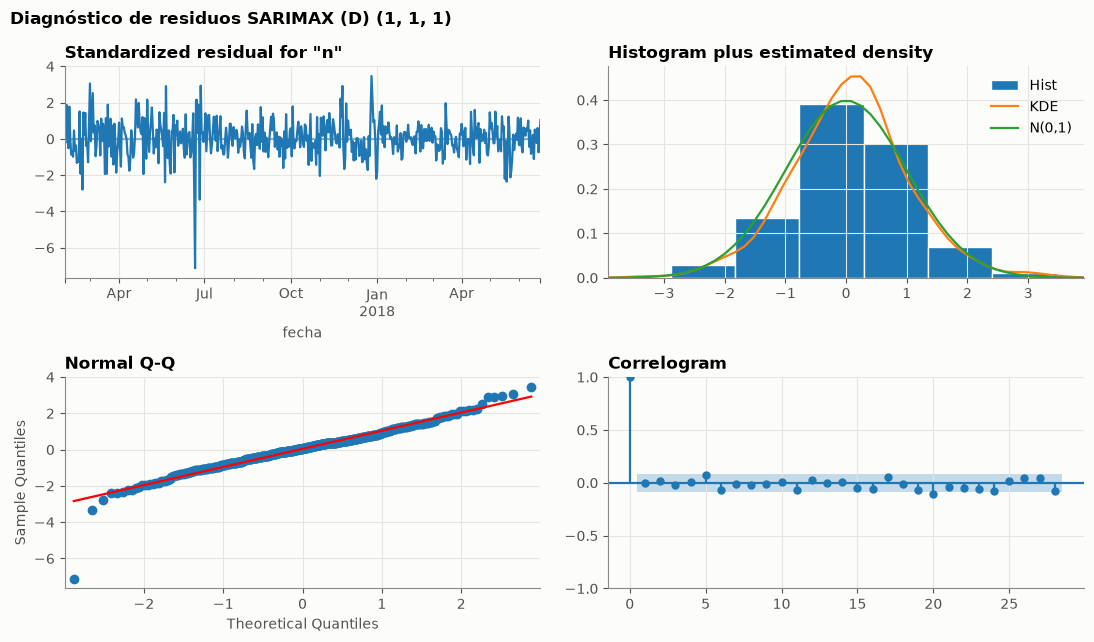

In [17]:
# Se elige la especificación SARIMAX con menor MAE de validación (sin días de paro)
NOMBRE_SARIMAX = comparacion_sarimax.drop("SARIMA")["MAE"].idxmin()
ESPEC_SARIMAX = ESPECS[NOMBRE_SARIMAX]
ESPEC_SARIMA = ESPECS["SARIMA"]
print("Especificación SARIMAX elegida:", NOMBRE_SARIMAX, ESPEC_SARIMAX["orden"], ESPEC_SARIMAX["orden_est"])

val_sarima = val_candidatos["SARIMA"]
val_sarimax = val_candidatos[NOMBRE_SARIMAX].assign(modelo="SARIMAX")

res_sel, cols_sel = ajustar_sarimax(y, INICIO_TEST - UN_DIA, **ESPEC_SARIMAX)
print(res_sel.summary().tables[1])

# Diagnóstico de residuos: Ljung-Box (H0: residuos sin autocorrelación)
lb = acorr_ljungbox(res_sel.resid[8:], lags=[7, 14, 21, 28])
print("\nLjung-Box sobre residuos (ajuste hasta el inicio de la prueba):\n", lb.round(4))

fig = res_sel.plot_diagnostics(figsize=(11, 6.5), lags=28)
fig.suptitle(f"Diagnóstico de residuos {NOMBRE_SARIMAX} {ESPEC_SARIMAX['orden']}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "B_07_diagnostico_sarimax")
plt.show()

## 8. Modelo de ML: LightGBM con estrategia directa

**Estrategia multi-paso: directa con el horizonte como variable** (un solo modelo para h = 1…28).

* Cada fila de `sql/B_03_features_ml.sql` es un par (origen, h): las variables se calculan **solo con datos hasta el cierre del origen** (ventanas `ROWS … PRECEDING AND CURRENT ROW`), y de la fecha objetivo solo se usan variables de **calendario**, que se conocen de antemano.
* Frente a la estrategia **recursiva** (predecir t+1, reinyectar la predicción como rezago, etc.), la directa (i) no acumula el error de sus propias predicciones a lo largo de 28 pasos, y (ii) permite construir **toda** la tabla en SQL, como exige el taller para ventanas temporales: con la recursiva habría que recalcular los rezagos en Python dentro del bucle de pronóstico. El costo es que el modelo no impone coherencia entre horizontes, lo cual no es un problema para un plan diario.
* Usar un solo modelo con `horizonte` como variable (en vez de 28 modelos separados) multiplica por 28 las filas de entrenamiento y deja que los horizontes compartan lo que aprenden sobre el día de la semana y los eventos.

**Objetivo relativo.** Los árboles no extrapolan: si la demanda sube por encima de lo visto en entrenamiento, un árbol nunca predice más allá de su hoja máxima. Por eso el objetivo y los rezagos se expresan como **log-razones respecto a la media de los últimos 28 días** en el origen: `log(1+y_{o+h}) − log(1+media_28_o)`. El modelo aprende la *forma* (día de la semana, eventos, momentum) y el nivel lo aporta `media_28`.

**Variables:** horizonte; calendario del día objetivo (día de la semana, día del mes, feriado, BF, post-BF, fiestas, paro); rezagos relativos 0–6; momentum `media_7/media_28`; tendencia `media_28/media_91`; coeficiente de variación de 28 días; número de días atípicos en la ventana; último valor y media de 4 semanas del mismo día de la semana.

In [18]:
VARIABLES = ["horizonte", "dia_semana", "dia_mes", "es_feriado", "black_friday", "post_black_friday",
             "fiestas_fin_anio", "paro_camioneros",
             "r_lag_0", "r_lag_1", "r_lag_2", "r_lag_3", "r_lag_4", "r_lag_5", "r_lag_6",
             "r_media_7", "r_tendencia_28_91", "cv_28", "n_atipicos_28", "r_ult_mismo_dia", "r_mismo_dia_4s"]


def construir_tabla_ml(con, fin_serie, estado=None):
    """Crea las tablas temporales serie_b y calendario_b y devuelve la tabla (origen, horizonte)."""
    crear_tabla_temporal(con, "serie_b", "B_01_serie_diaria.sql", [FECHA_INICIO.date(), fin_serie.date(), estado])
    crear_tabla_temporal(con, "calendario_b", "B_02_calendario.sql",
                         [FECHA_INICIO.date(), (FECHA_FIN + pd.Timedelta(days=H)).date()])
    tabla = consultar(con, "B_03_features_ml.sql")
    for c in ["fecha_origen", "fecha_objetivo"]:
        tabla[c] = pd.to_datetime(tabla[c])
    return tabla


tabla_ml = construir_tabla_ml(con, FECHA_FIN)
print(tabla_ml.shape, "| orígenes desde", tabla_ml["fecha_origen"].min().date())
tabla_ml.head(3).T

(14168, 26) | orígenes desde 2017-04-01


,0,1,2
fecha_origen,2017-04-01 00:00:00,2017-04-01 00:00:00,2017-04-01 00:00:00
horizonte,1,2,3
fecha_objetivo,2017-04-02 00:00:00,2017-04-03 00:00:00,2017-04-04 00:00:00
y_objetivo,65,72,96
objetivo_rel,-0.283208,-0.182403,0.101848
media_28,86.607143,86.607143,86.607143
dia_semana,7,1,2
dia_mes,2,3,4
es_feriado,0,0,0
black_friday,0,0,0


**Prueba de no-fuga.** Si las variables de un origen O solo dependen de datos ≤ O, entonces recalcular la tabla con la serie **truncada en O** debe dar exactamente las mismas variables para ese origen. Se verifica para varios orígenes (incluido el primero de prueba).

In [19]:
for o in [ORIGENES_VAL[0], ORIGENES_VAL[10], ORIGENES_TEST[0]]:
    truncada = construir_tabla_ml(con, o)
    a = truncada[truncada["fecha_origen"] == o].sort_values("horizonte")[VARIABLES + ["media_28"]]
    b = tabla_ml[tabla_ml["fecha_origen"] == o].sort_values("horizonte")[VARIABLES + ["media_28"]]
    assert np.allclose(a.values.astype(float), b.values.astype(float)), f"fuga en {o.date()}"
    print(f"Origen {o.date()}: variables idénticas con la serie truncada -> sin fuga")

tabla_ml = construir_tabla_ml(con, FECHA_FIN)   # se restaura la tabla completa

Origen 2018-01-07: variables idénticas con la serie truncada -> sin fuga
Origen 2018-03-18: variables idénticas con la serie truncada -> sin fuga
Origen 2018-06-24: variables idénticas con la serie truncada -> sin fuga


In [20]:
BASE_LGBM = dict(objective="regression", learning_rate=0.03, subsample=0.8, subsample_freq=1,
                 colsample_bytree=0.8, min_child_samples=40, reg_lambda=1.0,
                 random_state=SEMILLA, n_jobs=1, deterministic=True, force_row_wise=True, verbose=-1)


def entrenar_lgbm(tabla, o, params):
    """Entrena solo con filas cuyo objetivo ya se había observado en el origen o."""
    tr = tabla[(tabla["fecha_objetivo"] <= o) & (tabla["fecha_objetivo"] >= INICIO_AJUSTE)]
    modelo = lgb.LGBMRegressor(**{**BASE_LGBM, **params})
    modelo.fit(tr[VARIABLES], tr["objetivo_rel"])
    return modelo


def pronostico_lgbm(tabla, o, fechas, params):
    modelo = entrenar_lgbm(tabla, o, params)
    filas = tabla[tabla["fecha_origen"] == o].set_index("fecha_objetivo").loc[fechas]
    X = filas[VARIABLES].copy()
    X["paro_camioneros"] = 0                       # un paro no se puede anticipar
    nivel = np.log1p(filas["media_28"].values)
    return pd.DataFrame({"yhat": np.expm1(modelo.predict(X) + nivel)})


# Búsqueda de hiperparámetros con el walk-forward de validación (sin días de paro)
GRILLA = [{"num_leaves": nl, "n_estimators": ne, "objective": obj}
          for nl in (7, 15, 31) for ne in (300, 600) for obj in ("regression", "l1")]
filas_grid = []
for params in GRILLA:
    pred = sin_paro(walk_forward(y, "LightGBM", partial(pronostico_lgbm, tabla_ml, params=params), ORIGENES_VAL))
    mae_origen = pred.assign(ae=(pred["y"] - pred["yhat"]).abs()).groupby("origen")["ae"].mean()
    filas_grid.append({**params, "MAE medio": mae_origen.mean(), "MAE desv": mae_origen.std()})
tabla_grid = pd.DataFrame(filas_grid).sort_values("MAE medio").reset_index(drop=True).round(2)
tabla_grid

,num_leaves,n_estimators,objective,MAE medio,MAE desv
0,7,300,l1,38.40,19.62
1,7,600,l1,38.62,18.93
2,15,300,l1,39.26,19.31
3,15,600,l1,39.38,19.18
4,7,300,regression,40.12,18.67
5,31,300,l1,40.21,19.39
6,31,600,l1,40.52,19.34
7,7,600,regression,40.71,19.11
8,15,300,regression,42.52,19.16
9,15,600,regression,43.70,18.70


Hiperparámetros elegidos: {'num_leaves': 7, 'n_estimators': 300, 'objective': 'l1'}


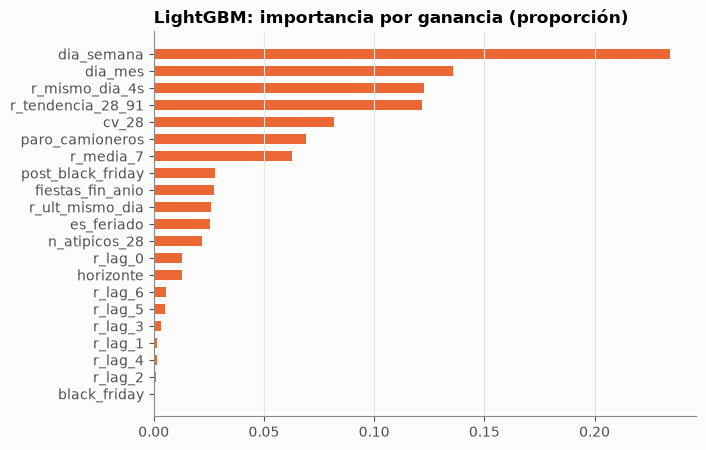

In [21]:
MEJORES_PARAMS = tabla_grid.loc[0, ["num_leaves", "n_estimators", "objective"]].to_dict()
MEJORES_PARAMS = {k: (int(v) if k != "objective" else v) for k, v in MEJORES_PARAMS.items()}
print("Hiperparámetros elegidos:", MEJORES_PARAMS)

val_lgbm = walk_forward(y, "LightGBM", partial(pronostico_lgbm, tabla_ml, params=MEJORES_PARAMS), ORIGENES_VAL)

# Importancia (ganancia) del modelo entrenado con todo lo anterior a la prueba
modelo_imp = entrenar_lgbm(tabla_ml, INICIO_TEST - UN_DIA, MEJORES_PARAMS)
imp = pd.Series(modelo_imp.booster_.feature_importance("gain"), index=VARIABLES)
imp = (imp / imp.sum()).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values, color=COLORES["LightGBM"], height=0.6)
ax.set_title("LightGBM: importancia por ganancia (proporción)")
ax.grid(axis="y", visible=False)
guardar(fig, "B_08_importancia_lgbm")
plt.show()

## 9. Comparación en validación y selección del modelo

La selección se hace **solo** con la validación *walk-forward* (21 orígenes). La métrica principal es el MAE sin los días del paro; también se reporta la desviación del MAE entre orígenes como medida de estabilidad.

In [22]:
VAL = pd.concat([val_ingenuo, val_ing_est, val_sarima, val_sarimax, val_lgbm], ignore_index=True)
ORDEN_MODELOS = ["Ingenuo", "Ingenuo estacional", "SARIMA", "SARIMAX", "LightGBM"]


def resumen(df):
    m = metricas(df)
    por_origen = df.assign(ae=(df["y"] - df["yhat"]).abs()).groupby(["modelo", "origen"])["ae"].mean()
    m["MAE desv. orígenes"] = por_origen.groupby("modelo").std().round(2)
    ref = m.loc["Ingenuo estacional", "MAE"]
    m["mejora vs ing. est. %"] = (100 * (1 - m["MAE"] / ref)).round(1)
    return m.reindex(ORDEN_MODELOS)


print("Validación SIN días de paro (criterio de selección)")
display(resumen(sin_paro(VAL)))
print("Validación CON días de paro (referencia)")
display(resumen(VAL)[["MAE", "RMSE", "MAPE", "sMAPE"]])

Validación SIN días de paro (criterio de selección)


,MAE,RMSE,MAPE,sMAPE,n,MAE desv. orígenes,mejora vs ing. est. %
modelo,,,,,,,
Ingenuo,54.94,67.82,22.25,25.16,544,20.58,-45.1
Ingenuo estacional,37.86,49.72,16.34,16.76,544,13.60,0.0
SARIMA,34.89,43.98,15.55,15.10,544,16.03,7.8
SARIMAX,29.01,36.45,12.38,12.27,544,10.72,23.4
LightGBM,36.14,46.18,16.52,15.10,544,19.62,4.5


Validación CON días de paro (referencia)


,MAE,RMSE,MAPE,sMAPE
modelo,,,,
Ingenuo,55.10,67.59,24.16,26.04
Ingenuo estacional,44.59,61.38,22.39,20.15
SARIMA,40.61,53.75,20.95,18.26
SARIMAX,34.73,46.39,17.64,15.56
LightGBM,43.40,58.03,22.92,18.91


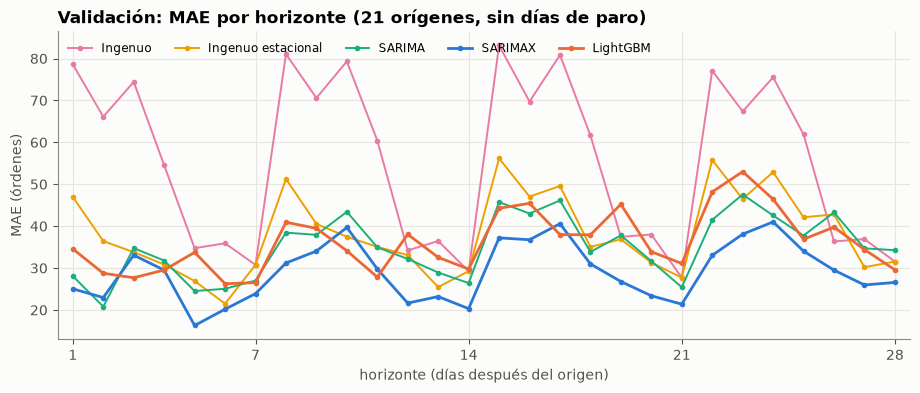

In [23]:
def grafico_por_horizonte(df, titulo, nombre, metrica="MAE"):
    e = df.assign(ae=(df["y"] - df["yhat"]).abs(), ape=100 * (df["y"] - df["yhat"]).abs() / df["y"])
    col = "ae" if metrica == "MAE" else "ape"
    tabla = e.groupby(["modelo", "horizonte"])[col].mean().unstack(0)[ORDEN_MODELOS]
    fig, ax = plt.subplots(figsize=(11, 4))
    for m in ORDEN_MODELOS:
        ax.plot(tabla.index, tabla[m], color=COLORES[m], lw=2 if m in ("SARIMAX", "LightGBM") else 1.4,
                marker="o", ms=3)
    ax.set_xlim(0.5, H + 0.5)
    ax.set_xticks([1, 7, 14, 21, 28])
    ax.set_xlabel("horizonte (días después del origen)")
    ax.set_ylabel(metrica + (" (órdenes)" if metrica == "MAE" else " (%)"))
    ax.set_title(titulo)
    ax.legend(ORDEN_MODELOS, loc="upper left", ncols=5, fontsize=8.5)
    guardar(fig, nombre)
    plt.show()
    return tabla


_ = grafico_por_horizonte(sin_paro(VAL), "Validación: MAE por horizonte (21 orígenes, sin días de paro)", "B_09_mae_horizonte_val")

In [24]:
mae_val = resumen(sin_paro(VAL))["MAE"]
MODELO_ELEGIDO = mae_val.drop(["Ingenuo", "Ingenuo estacional"]).idxmin()
print("Modelo elegido en validación:", MODELO_ELEGIDO)

Modelo elegido en validación: SARIMAX


## 10. Evaluación final en prueba (se usa una sola vez)

Todos los modelos se reajustan en cada uno de los 5 orígenes de prueba con los datos reales hasta ese domingo, con los órdenes e hiperparámetros **ya fijados en validación**.

In [25]:
%%time
TEST = pd.concat([
    walk_forward(y, "Ingenuo", partial(pronostico_ingenuo, y), ORIGENES_TEST),
    walk_forward(y, "Ingenuo estacional", partial(pronostico_ingenuo_estacional, y), ORIGENES_TEST),
    walk_forward(y, "SARIMA", partial(pronostico_sarimax, y, **ESPEC_SARIMA), ORIGENES_TEST),
    walk_forward(y, "SARIMAX", partial(pronostico_sarimax, y, **ESPEC_SARIMAX), ORIGENES_TEST),
    walk_forward(y, "LightGBM", partial(pronostico_lgbm, tabla_ml, params=MEJORES_PARAMS), ORIGENES_TEST),
], ignore_index=True)
assert TEST["fecha"].max() <= FECHA_FIN and TEST["fecha"].min() >= INICIO_TEST
resumen_test = resumen(TEST)
resumen_test

CPU times: total: 6.98 s
Wall time: 6.91 s


,MAE,RMSE,MAPE,sMAPE,n,MAE desv. orígenes,mejora vs ing. est. %
modelo,,,,,,,
Ingenuo,77.61,94.06,32.33,37.69,140,29.18,-16.8
Ingenuo estacional,66.42,84.58,29.83,32.56,140,34.11,0.0
SARIMA,59.35,73.68,26.98,28.46,140,29.04,10.6
SARIMAX,61.84,76.11,27.54,29.73,140,29.89,6.9
LightGBM,53.47,66.51,26.80,24.62,140,14.80,19.5


In [26]:
# Error por semana del horizonte (h 1-7, 8-14, 15-21, 22-28)
por_semana = metricas(semana_horizonte(TEST), por=("modelo", "semana_h"))[["MAE", "RMSE", "MAPE", "sMAPE"]]
por_semana["MAE"].unstack().reindex(ORDEN_MODELOS)

semana_h,sem 1,sem 2,sem 3,sem 4
modelo,,,,
Ingenuo,49.63,69.83,94.34,96.63
Ingenuo estacional,50.89,65.54,75.14,74.11
SARIMA,35.81,61.31,73.92,66.37
SARIMAX,35.49,62.59,75.56,73.73
LightGBM,46.28,59.30,60.56,47.73


RMSE y sMAPE por semana del horizonte


RMSE                         sMAPE                     
semana_h            sem 1  sem 2   sem 3   sem 4  sem 1  sem 2  sem 3  sem 4
modelo                                                                      
Ingenuo             58.87  84.25  105.97  116.61  26.41  35.68  45.18  43.47
Ingenuo estacional  63.78  77.85   93.28   98.91  27.50  33.85  35.84  33.05
SARIMA              45.15  68.87   85.38   87.41  19.87  31.18  34.27  28.52
SARIMAX             45.84  69.88   87.49   92.38  19.83  31.77  35.13  32.18
LightGBM            60.47  68.26   75.10   61.16  24.05  28.63  26.63  19.17

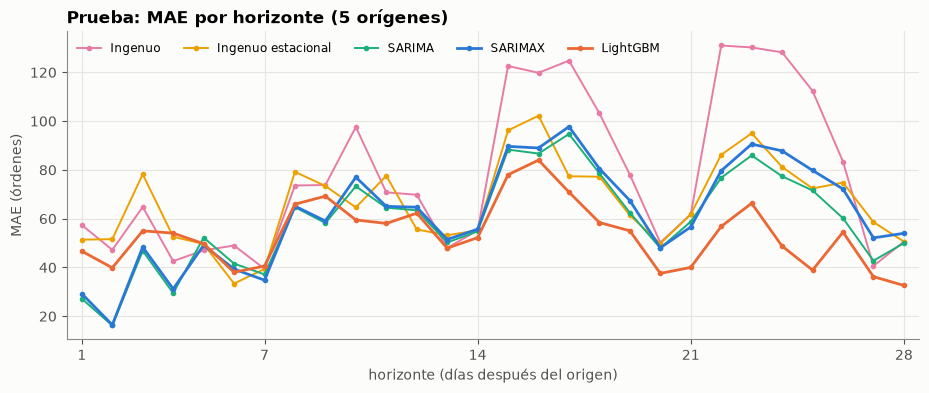

In [27]:
print("RMSE y sMAPE por semana del horizonte")
display(por_semana[["RMSE", "sMAPE"]].unstack().reindex(ORDEN_MODELOS))
tabla_h_test = grafico_por_horizonte(TEST, "Prueba: MAE por horizonte (5 orígenes)", "B_10_mae_horizonte_test")

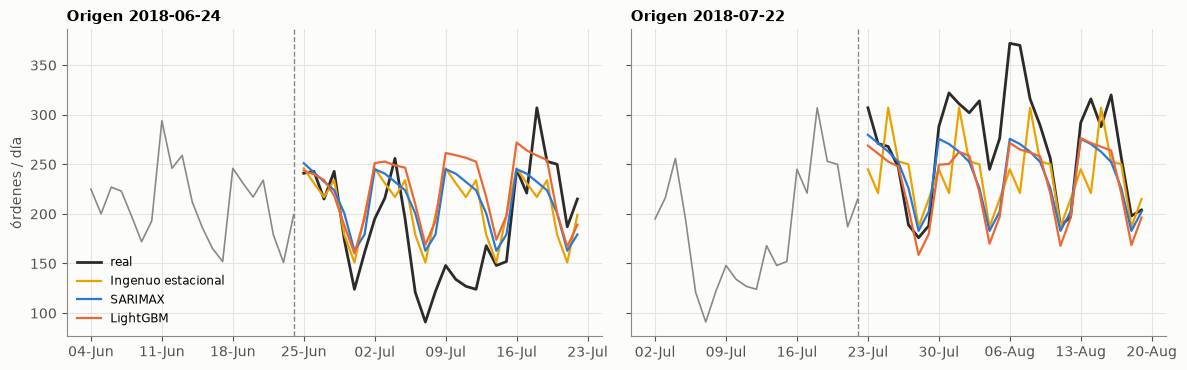

In [28]:
# Pronósticos vs. real en dos orígenes de prueba
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, o in zip(ejes, [ORIGENES_TEST[0], ORIGENES_TEST[-1]]):
    trozo = TEST[TEST["origen"] == o]
    hist = y[o - pd.Timedelta(days=20):o]
    ax.plot(hist.index, hist.values, color=COLOR_TENUE, lw=1.2)
    real = trozo[trozo["modelo"] == "SARIMAX"]
    ax.plot(real["fecha"], real["y"], color=COLOR_REAL, lw=2, label="real")
    for m in ["Ingenuo estacional", "SARIMAX", "LightGBM"]:
        t = trozo[trozo["modelo"] == m]
        ax.plot(t["fecha"], t["yhat"], color=COLORES[m], lw=1.6, label=m)
    ax.axvline(o, color=COLOR_TENUE, ls="--", lw=1)
    ax.set_title(f"Origen {o.date()}", fontsize=10.5)
    formato_fechas(ax)
ejes[0].legend(fontsize=8.5, loc="lower left")
ejes[0].set_ylabel("órdenes / día")
fig.tight_layout()
guardar(fig, "B_11_pronosticos_test")
plt.show()

In [29]:
# Diagnóstico: ¿cuánto error explican los partidos de Brasil en el Mundial?
diag = TEST.assign(ape=100 * (TEST["y"] - TEST["yhat"]).abs() / TEST["y"],
                   sesgo=100 * (TEST["yhat"] - TEST["y"]) / TEST["y"],
                   partido=cal.loc[TEST["fecha"], "partido_brasil"].values)
diag.groupby(["modelo", "partido"])[["ape", "sesgo"]].mean().round(1).unstack().reindex(ORDEN_MODELOS)

ape       sesgo      
partido                0     1     0     1
modelo                                    
Ingenuo             32.6  24.9 -19.7  14.9
Ingenuo estacional  29.9  28.5 -10.2  28.5
SARIMA              26.7  35.5  -8.5  35.5
SARIMAX             27.3  32.7 -11.2  32.7
LightGBM            26.2  42.6   2.2  42.6

**¿Por qué la prueba es más difícil que la validación?** Se desagrega el error por origen y el sesgo por mes. Este análisis es *post hoc*: describe la prueba, no se usa para cambiar ningún modelo.

In [30]:
diag["periodo"] = np.where(diag["fecha"] < "2018-08-01", "25-jun a 31-jul", "1 a 19-ago")
print("MAE por origen de prueba")
display(diag.assign(ae=(diag["y"] - diag["yhat"]).abs())
            .pivot_table(index="origen", columns="modelo", values="ae", aggfunc="mean")[ORDEN_MODELOS].round(1))
print("Sesgo medio % ((pronóstico - real) / real) por periodo")
display(diag.pivot_table(index="periodo", columns="modelo", values="sesgo", aggfunc="mean")[ORDEN_MODELOS].round(1))
print("Promedio diario real:", y["2018-06-25":"2018-07-31"].mean().round(1), "(jul) vs", y["2018-08-01":].mean().round(1), "(ago)")

MAE por origen de prueba


modelo,Ingenuo,Ingenuo estacional,SARIMA,SARIMAX,LightGBM
origen,,,,,
2018-06-24,47.5,40.6,45.5,42.3,48.5
2018-07-01,56.3,46.5,41.4,43.5,49.0
2018-07-08,106.0,80.6,84.2,84.5,51.5
2018-07-15,111.2,120.2,96.1,102.8,78.7
2018-07-22,67.0,44.2,29.5,36.1,39.7


Sesgo medio % ((pronóstico - real) / real) por periodo


modelo,Ingenuo,Ingenuo estacional,SARIMA,SARIMAX,LightGBM
periodo,,,,,
1 a 19-ago,-33.4,-28.7,-25.4,-29.5,-23.5
25-jun a 31-jul,-13.3,-2.0,-0.5,-2.8,13.0


Promedio diario real: 203.6 (jul) vs 279.5 (ago)


## 11. Incertidumbre: intervalos de predicción y cobertura empírica

Se comparan dos enfoques:

1. **Paramétrico (SARIMAX):** intervalos del modelo en escala log, transformados con `expm1`. Suponen residuos normales y que el modelo está bien especificado.
2. **Conformal por horizonte (SARIMAX y LightGBM):** con los residuos en escala log de la **validación** (sin días de paro) se toma, para cada semana del horizonte, el cuantil corregido `⌈(n+1)(1−α)⌉/n` del error absoluto; el intervalo de prueba es `expm1(log(1+ŷ) ± q)`. No supone normalidad, solo intercambiabilidad aproximada de los errores, y el ancho crece con el horizonte porque se calibra por semana de h.

La **cobertura empírica** es la proporción de días de prueba en que el valor real cayó dentro del intervalo; lo ideal es que se acerque al nivel nominal (80 % y 95 %).

In [31]:
def cuantiles_conformales(df_val, niveles=(0.80, 0.95)):
    r = semana_horizonte(df_val).assign(err=lambda d: (np.log1p(d["y"]) - np.log1p(d["yhat"])).abs())
    salida = {}
    for sem, g in r.groupby("semana_h"):
        n = len(g)
        salida[sem] = {nivel: np.quantile(g["err"], min(1, np.ceil((n + 1) * nivel) / n)) for nivel in niveles}
    return salida


def aplicar_conformal(df, q):
    d = semana_horizonte(df).copy()
    base = np.log1p(d["yhat"])
    for nivel, sufijo in [(0.80, "80"), (0.95, "95")]:
        qq = d["semana_h"].map(lambda s: q[s][nivel])
        d["lo" + sufijo] = np.expm1(base - qq)
        d["hi" + sufijo] = np.expm1(base + qq)
    return d


def cobertura(df, metodo):
    return pd.Series({
        "método": metodo,
        "cobertura 80 %": round(100 * ((df["y"] >= df["lo80"]) & (df["y"] <= df["hi80"])).mean(), 1),
        "ancho medio 80 %": round((df["hi80"] - df["lo80"]).mean(), 1),
        "cobertura 95 %": round(100 * ((df["y"] >= df["lo95"]) & (df["y"] <= df["hi95"])).mean(), 1),
        "ancho medio 95 %": round((df["hi95"] - df["lo95"]).mean(), 1),
    })


q_sarimax = cuantiles_conformales(sin_paro(val_sarimax))
q_lgbm = cuantiles_conformales(sin_paro(val_lgbm))
test_sarimax = TEST[TEST["modelo"] == "SARIMAX"]
test_sarimax_conf = aplicar_conformal(test_sarimax.drop(columns=["lo80", "hi80", "lo95", "hi95"]), q_sarimax)
test_lgbm_conf = aplicar_conformal(TEST[TEST["modelo"] == "LightGBM"], q_lgbm)

tabla_cobertura = pd.DataFrame([
    cobertura(sin_paro(val_sarimax), "SARIMAX paramétrico — validación"),
    cobertura(test_sarimax, "SARIMAX paramétrico — prueba"),
    cobertura(test_sarimax_conf, "SARIMAX conformal — prueba"),
    cobertura(test_lgbm_conf, "LightGBM conformal — prueba"),
]).set_index("método")
tabla_cobertura

,cobertura 80 %,ancho medio 80 %,cobertura 95 %,ancho medio 95 %
método,,,,
SARIMAX paramétrico — validación,97.1,157.6,100.0,247.5
SARIMAX paramétrico — prueba,54.3,125.6,75.0,196.9
SARIMAX conformal — prueba,39.3,77.3,51.4,115.9
LightGBM conformal — prueba,65.0,114.6,80.0,178.3


In [32]:
# Cobertura del 95 % por semana del horizonte en prueba
cob_sem = pd.DataFrame({
    nombre: semana_horizonte(df).assign(dentro=lambda d: (d["y"] >= d["lo95"]) & (d["y"] <= d["hi95"]))
                                .groupby("semana_h")["dentro"].mean().mul(100).round(1)
    for nombre, df in [("SARIMAX paramétrico", test_sarimax), ("SARIMAX conformal", test_sarimax_conf),
                       ("LightGBM conformal", test_lgbm_conf)]
})
print("Cobertura empírica del intervalo del 95 % por semana del horizonte (prueba)")
cob_sem

Cobertura empírica del intervalo del 95 % por semana del horizonte (prueba)


,SARIMAX paramétrico,SARIMAX conformal,LightGBM conformal
semana_h,,,
sem 1,80.0,62.9,71.4
sem 2,74.3,42.9,80.0
sem 3,68.6,42.9,77.1
sem 4,77.1,57.1,91.4


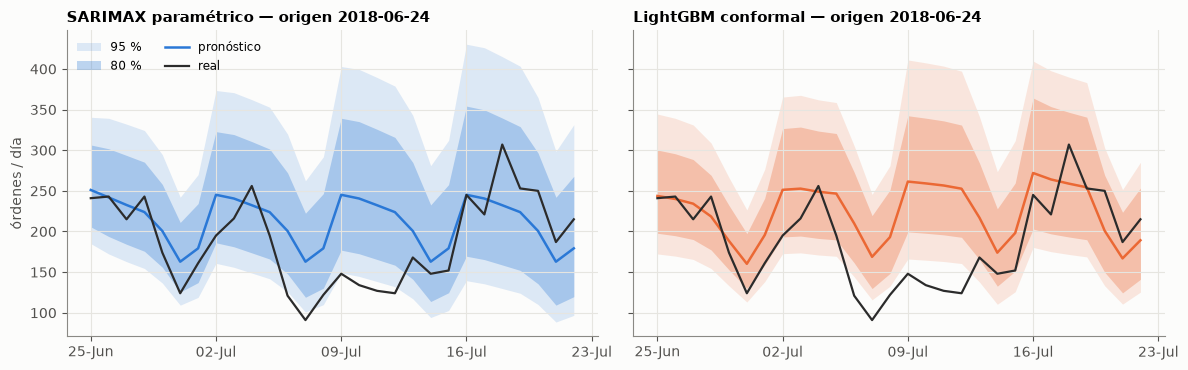

In [33]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
o = ORIGENES_TEST[0]
for ax, (nombre, df, color) in zip(ejes, [("SARIMAX paramétrico", test_sarimax, COLORES["SARIMAX"]),
                                          ("LightGBM conformal", test_lgbm_conf, COLORES["LightGBM"])]):
    t = df[df["origen"] == o]
    ax.fill_between(t["fecha"], t["lo95"], t["hi95"], color=color, alpha=0.15, lw=0, label="95 %")
    ax.fill_between(t["fecha"], t["lo80"], t["hi80"], color=color, alpha=0.30, lw=0, label="80 %")
    ax.plot(t["fecha"], t["yhat"], color=color, lw=1.8, label="pronóstico")
    ax.plot(t["fecha"], t["y"], color=COLOR_REAL, lw=1.6, label="real")
    ax.set_title(f"{nombre} — origen {o.date()}", fontsize=10.5)
    formato_fechas(ax)
ejes[0].legend(fontsize=8.5, loc="upper left", ncols=2)
ejes[0].set_ylabel("órdenes / día")
fig.tight_layout()
guardar(fig, "B_12_intervalos")
plt.show()

## 12. Pronóstico operativo: 20-ago a 16-sep-2018

Respuesta directa a la pregunta de negocio. Se reajusta el modelo elegido en validación con **todos** los datos hasta el 19-ago-2018 y se pronostican los 28 días siguientes, con intervalo conformal del 80 % y 95 % calibrado en validación. No hay valores reales para compararlo (el extracto está truncado), por eso es un pronóstico y no una evaluación. Se guarda en `resultados/B_pronostico_28d.csv` para el Módulo D (alertas diarias esperadas = demanda proyectada × tasa de alerta del Módulo A).

Modelo: SARIMAX. Totales semanales (el intervalo semanal sumando extremos diarios es conservador):


,yhat,lo80,hi80
semana,,,
2018-08-20/2018-08-26,1806.0,1509.0,2162.0
2018-08-27/2018-09-02,1813.0,1529.0,2148.0
2018-09-03/2018-09-09,1770.0,1421.0,2203.0
2018-09-10/2018-09-16,1813.0,1438.0,2284.0


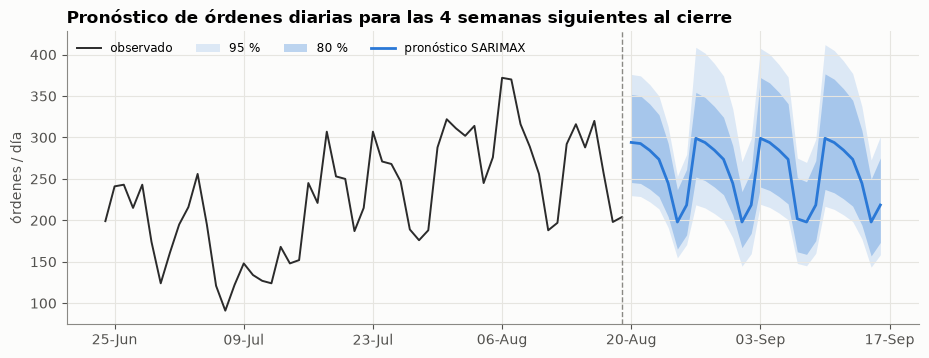

,fecha,dia,feriado,yhat,lo80,hi80,lo95,hi95
0,2018-08-20,Monday,NaN,294.0,246.0,352.0,230.0,376.0
1,2018-08-21,Tuesday,NaN,293.0,245.0,350.0,229.0,374.0
2,2018-08-22,Wednesday,NaN,285.0,238.0,341.0,222.0,364.0
3,2018-08-23,Thursday,NaN,274.0,229.0,327.0,214.0,350.0
4,2018-08-24,Friday,NaN,245.0,204.0,293.0,191.0,313.0
5,2018-08-25,Saturday,NaN,198.0,165.0,237.0,155.0,253.0
6,2018-08-26,Sunday,NaN,218.0,182.0,262.0,171.0,280.0
7,2018-08-27,Monday,NaN,299.0,252.0,354.0,219.0,409.0
8,2018-08-28,Tuesday,NaN,294.0,248.0,348.0,215.0,402.0
9,2018-08-29,Wednesday,NaN,285.0,240.0,338.0,208.0,389.0


In [34]:
fechas_futuras = pd.date_range(FECHA_FIN + UN_DIA, periods=H, freq="D")
if MODELO_ELEGIDO == "LightGBM":
    futuro = pronostico_lgbm(tabla_ml, FECHA_FIN, fechas_futuras, MEJORES_PARAMS)
    q_final = q_lgbm
else:
    espec = ESPEC_SARIMAX if MODELO_ELEGIDO == "SARIMAX" else ESPEC_SARIMA
    futuro = pronostico_sarimax(y, FECHA_FIN, fechas_futuras, **espec)[["yhat"]]
    q_final = q_sarimax
futuro["horizonte"] = np.arange(1, H + 1)
futuro = aplicar_conformal(futuro, q_final)
futuro.insert(0, "fecha", fechas_futuras)
futuro["dia"] = futuro["fecha"].dt.day_name()
futuro["feriado"] = cal.loc[fechas_futuras, "nombre_feriado"].values
futuro_out = futuro[["fecha", "dia", "feriado", "yhat", "lo80", "hi80", "lo95", "hi95"]].round(0)
futuro_out.to_csv(RUTA_RES / "B_pronostico_28d.csv", index=False)

semanal = futuro.assign(semana=futuro["fecha"].dt.to_period("W-SUN").astype(str)) \
                .groupby("semana")[["yhat", "lo80", "hi80"]].sum().round(0)
print(f"Modelo: {MODELO_ELEGIDO}. Totales semanales (el intervalo semanal sumando extremos diarios es conservador):")
display(semanal)

fig, ax = plt.subplots(figsize=(11, 3.8))
hist = y[FECHA_FIN - pd.Timedelta(days=56):]
ax.plot(hist.index, hist.values, color=COLOR_REAL, lw=1.4, label="observado")
color = COLORES[MODELO_ELEGIDO]
ax.fill_between(futuro["fecha"], futuro["lo95"], futuro["hi95"], color=color, alpha=0.15, lw=0, label="95 %")
ax.fill_between(futuro["fecha"], futuro["lo80"], futuro["hi80"], color=color, alpha=0.30, lw=0, label="80 %")
ax.plot(futuro["fecha"], futuro["yhat"], color=color, lw=2, label=f"pronóstico {MODELO_ELEGIDO}")
ax.axvline(FECHA_FIN, color=COLOR_TENUE, ls="--", lw=1)
ax.set_title("Pronóstico de órdenes diarias para las 4 semanas siguientes al cierre")
ax.set_ylabel("órdenes / día")
ax.legend(loc="upper left", ncols=4, fontsize=8.5)
formato_fechas(ax, semanas=2)
guardar(fig, "B_13_pronostico_operativo")
plt.show()
futuro_out.head(10)

## 13. Extensión opcional: serie de São Paulo

São Paulo concentra ~42 % de las órdenes. Se reutiliza la misma consulta `B_01` con el parámetro `estado = 'SP'` y el mismo pipeline (órdenes SARIMAX e hiperparámetros de LightGBM **heredados** de la serie nacional, sin reajustar, para no tocar la prueba).

In [35]:
%%time
serie_sp = consultar(con, "B_01_serie_diaria.sql", [FECHA_INICIO.date(), FECHA_FIN.date(), "SP"])
serie_sp["fecha"] = pd.to_datetime(serie_sp["fecha"])
y_sp = serie_sp.set_index("fecha")["n_ordenes"].asfreq("D")
print(f"SP: {y_sp.sum():,} órdenes ({100 * y_sp.sum() / y.sum():.1f} % del total)")

tabla_ml_sp = construir_tabla_ml(con, FECHA_FIN, estado="SP")
TEST_SP = pd.concat([
    walk_forward(y_sp, "Ingenuo estacional", partial(pronostico_ingenuo_estacional, y_sp), ORIGENES_TEST),
    walk_forward(y_sp, "SARIMAX", partial(pronostico_sarimax, y_sp, **ESPEC_SARIMAX), ORIGENES_TEST),
    walk_forward(y_sp, "LightGBM", partial(pronostico_lgbm, tabla_ml_sp, params=MEJORES_PARAMS), ORIGENES_TEST),
], ignore_index=True)
tabla_ml = construir_tabla_ml(con, FECHA_FIN)   # se restauran las tablas temporales nacionales
metricas(TEST_SP).reindex(["Ingenuo estacional", "SARIMAX", "LightGBM"])

SP: 40,860 órdenes (41.7 % del total)


CPU times: total: 3.47 s
Wall time: 3.52 s


,MAE,RMSE,MAPE,sMAPE,n
modelo,,,,,
Ingenuo estacional,37.04,46.22,38.22,41.13,140
SARIMAX,35.46,42.92,36.74,39.16,140
LightGBM,27.63,33.79,33.26,29.04,140


In [36]:
# Resultados para el informe
resumen_test.to_csv(RUTA_RES / "B_metricas_test.csv")
resumen(sin_paro(VAL)).to_csv(RUTA_RES / "B_metricas_validacion.csv")
tabla_cobertura.to_csv(RUTA_RES / "B_cobertura_intervalos.csv")
TEST.to_csv(RUTA_RES / "B_pronosticos_test.csv", index=False)
con.close()
print("Archivos guardados en", RUTA_RES.resolve())

Archivos guardados en C:\Users\albei\Desktop\maestria_nueva\Semestre 2\Machine learning\Taller\resultados


## 14. Conclusiones

1. **La serie.** Entre feb-2017 y dic-2017 la demanda se triplicó; desde ene-2018 hay una meseta de ~230 órdenes/día que baja a ~205 en jun–jul y repunta a ~280 en agosto. La estacionalidad semanal es fuerte y estable (lunes ≈ +17 %, sábado ≈ −23 % frente a la media semanal). La serie en log es no estacionaria (ADF no rechaza, KPSS rechaza) y una diferencia regular basta para volverla estacionaria.
2. **Eventos.** Black Friday (×7.6 lo esperado), los días posteriores (×2.6), los feriados (−26 %) y las fiestas de fin de año (−49 %) se **modelan** con dummies porque son recurrentes y con fecha conocida. El paro de camioneros (−49 %) se **marca**: dummy en el ajuste, 0 al pronosticar y fuera de las métricas de validación. Los partidos de Brasil en el Mundial se usan solo para diagnóstico.
3. **Selección (validación walk-forward, 21 orígenes).** El SARIMAX con estacionalidad **determinística** (ARIMA(1,1,1) + dummies de día de la semana + eventos sobre log(1+y)) fue el mejor: MAE 29.0 frente a 37.9 del ingenuo estacional (−23 %) y 36.1 de LightGBM. La alternativa con diferencia estacional se descartó porque estimaba un MA estacional de −1 (no invertible), una señal de sobrediferenciación.
4. **Prueba (8 semanas, una sola vez).** Todos los modelos empeoran porque la prueba incluye dos cambios de régimen que no estaban en la historia: el valle de inicios de julio (Mundial) y el salto de nivel de agosto (+38 % frente a julio). Todos subestiman agosto entre 23 % y 30 %. LightGBM fue el más robusto (MAE 53.5, −19.5 % frente al ingenuo estacional) y SARIMAX quedó en 61.8 (−6.9 %). En los orígenes sin cambio de régimen (24-jun, 1-jul y 22-jul) los modelos estadísticos superan a LightGBM.
5. **Horizonte.** El error crece con el horizonte: en la semana 1, SARIMAX tiene un MAE de ~35 (sMAPE ~20 %), y en las semanas 3–4 llega a 70–75. LightGBM degrada menos con el horizonte.
6. **Incertidumbre.** Los intervalos paramétricos del SARIMAX cubrieron el 100 % en validación (algo anchos), pero solo el 75 % en prueba con un 95 % nominal. Los conformales calibrados en validación también subcubren en prueba (LightGBM 80 %). La razón es que los residuos de validación no representan el cambio de régimen de la prueba. Recomendación: recalibrar los intervalos cada semana con una ventana móvil de residuos recientes (conformal adaptativo) y vigilar el sesgo.
7. **Recomendación operativa.** Reajustar cada domingo; usar el SARIMAX como pronóstico base y LightGBM como contraste. Si los dos difieren en más del ~15 % o si el sesgo de la última semana supera ±15 %, el planeador revisa manualmente. Como trabajo futuro: combinar ambos (ensamble) y validarlo con el mismo protocolo, y agregar variables de campañas comerciales (que probablemente expliquen el salto de agosto).